<a href="https://colab.research.google.com/github/aryananand0/Math-344-Lab-Project-Fall-2026/blob/main/Notebooks/03_low_rank_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 3: Low-Rank Movie Predictions

I compare three ways of using the SVD to predict the same hidden ratings from Milestone 2.

## 1. Import my Milestone 2 functions

In [1]:
from pathlib import Path
import subprocess
import sys

# Use the local files if I opened the notebook from my checkout
repo = Path.cwd()
if not (repo / "Src").is_dir():
    repo = repo.parent
if not (repo / "Src").is_dir():
    repo = Path("Math-344-Lab-Project-Fall-2026")
    if not (repo / "Src").is_dir():
        subprocess.run(
            ["git", "clone", "-q", "https://github.com/aryananand0/Math-344-Lab-Project-Fall-2026.git", str(repo)],
            check=True
        )

sys.path.insert(0, str(repo.resolve() / "Src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from evaluate import rmse, split_ratings, to_matrix
from models import baseline_matrix, iterative_svd_predict, rank_k

I reuse the same split and error functions from Milestone 2. The baseline and both SVD helpers come from `Src/models.py`.

## 2. Load the same data and test split

In [2]:
import urllib.request
import zipfile

# Download MovieLens if the ratings file is missing
if not Path("ml-100k/u.data").is_file():
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )
    with zipfile.ZipFile("ml-100k.zip") as zipped:
        zipped.extractall()

ratings = pd.read_csv(
    "ml-100k/u.data", sep="\t",
    names=["user", "item", "rating", "time"]
)

# Keep the split method from my earlier milestone
train, test = split_ratings(ratings)
R = to_matrix(train)
known = ~np.isnan(R)

# These positions are the ratings I hid for testing
truth = test["rating"].to_numpy()
u = test["user"].to_numpy() - 1
i = test["item"].to_numpy() - 1

print("train:", len(train), "test:", len(test))
print("matrix size:", R.shape)
print("missing fraction:", round(1 - known.mean(), 4))

train: 90032 test: 9968
matrix size: (943, 1682)
missing fraction: 0.9432


I used the same `split_ratings()` function as Milestone 2. My repository's split may give slightly different counts from the sample output in the handout, so I compare my models using my own unchanged test set.

In [3]:
def score(P):
    # Only check ratings that were left out of training
    guesses = np.clip(P[u, i], 1, 5)
    return rmse(guesses, truth)

The score is RMSE on the hidden test ratings. Smaller values mean the predictions are closer to the actual ratings.

## 3. Score the baseline

In [4]:
B = baseline_matrix(R)
base_error = score(B)
print("baseline matrix:", B.shape)
print("baseline test RMSE:", round(base_error, 4))

baseline matrix: (943, 1682)
baseline test RMSE: 0.9545


The baseline uses the overall average along with how each user and movie tends to be rated. The SVD models need to improve on this error.

## 4. Model 1: Fill missing ratings with movie averages

In [5]:
# Start with the average rating across the entire matrix
mu = np.nanmean(R)
n_item = known.sum(axis=0)
item_mean = np.full(R.shape[1], mu)

# Use each movie's average when at least one rating exists
has_rating = n_item > 0
item_mean[has_rating] = (
    np.nansum(R, axis=0)[has_rating] / n_item[has_rating]
)

# Keep real ratings, and fill in missing ones with movie averages
F = np.where(known, R, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

Model 1 fills missing entries with the average for that movie before taking the SVD. This is easy to do, but most entries are guesses rather than real ratings.

## 5. Model 2: Subtract the baseline first

In [6]:
# A known residual is the actual rating minus the baseline
# For missing ratings, zero means no extra information yet
X = np.where(known, R - B, 0.0)
U2, s2, Vt2 = np.linalg.svd(X, full_matrices=False)

Model 2 lets SVD explain what the baseline missed. I add the baseline back after the rank-k approximation so the final predictions are still star ratings.

## 6. Test different ranks

In [7]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100, 200, 400, 943]
err1, err2 = [], []

for k in ks:
    # The first model predicts directly from the filled matrix
    err1.append(score(rank_k(U1, s1, Vt1, k)))

    # The second model predicts residuals and then adds the baseline
    err2.append(score(rank_k(U2, s2, Vt2, k) + B))

    print(f"k={k:3d}  model 1={err1[-1]:.4f}  model 2={err2[-1]:.4f}")

best1_k = ks[int(np.argmin(err1))]
best2_k = ks[int(np.argmin(err2))]
print("\nModel 1 best:", best1_k, round(min(err1), 4))
print("Model 2 best:", best2_k, round(min(err2), 4))

k=  1  model 1=1.0060  model 2=0.9428
k=  2  model 1=0.9917  model 2=0.9368
k=  3  model 1=0.9884  model 2=0.9356
k=  5  model 1=0.9790  model 2=0.9304
k= 10  model 1=0.9726  model 2=0.9256
k= 15  model 1=0.9742  model 2=0.9250
k= 20  model 1=0.9745  model 2=0.9261
k= 30  model 1=0.9763  model 2=0.9300
k= 50  model 1=0.9876  model 2=0.9363
k=100  model 1=1.0048  model 2=0.9453
k=200  model 1=1.0168  model 2=0.9500
k=400  model 1=1.0273  model 2=0.9543
k=943  model 1=1.0284  model 2=0.9545

Model 1 best: 10 0.9726
Model 2 best: 15 0.925


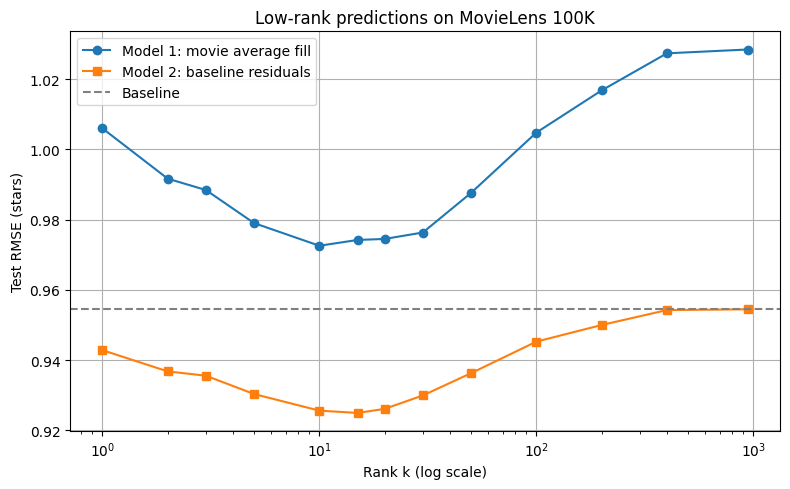

In [8]:
plt.figure(figsize=(8, 5))
plt.semilogx(ks, err1, "o-", label="Model 1: movie average fill")
plt.semilogx(ks, err2, "s-", label="Model 2: baseline residuals")
plt.axhline(base_error, color="gray", linestyle="--", label="Baseline")
plt.xlabel("Rank k (log scale)")
plt.ylabel("Test RMSE (stars)")
plt.title("Low-rank predictions on MovieLens 100K")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(repo / "Figures" / "rmse_vs_k.png", dpi=150)
plt.show()

This plot compares both models with the baseline. Using too few components can miss useful patterns, but using too many can fit noise or the temporary guesses in the missing entries.

In [9]:
# Print the conclusion using the results from this run
m1 = "beats" if min(err1) < base_error else "does not beat"
m2 = "beats" if min(err2) < base_error else "does not beat"
display(Markdown(
    f"**Result:** Model 1's lowest RMSE was **{min(err1):.4f}** at k={best1_k}, "
    f"so it {m1} the **{base_error:.4f}** baseline. "
    f"Model 2's lowest RMSE was **{min(err2):.4f}** at k={best2_k}, "
    f"so it {m2} the baseline. These ranks are only the best ones found "
    f"on this test set; Exercise 4 uses validation to choose k more fairly."
))

**Result:** Model 1's lowest RMSE was **0.9726** at k=10, so it does not beat the **0.9545** baseline. Model 2's lowest RMSE was **0.9250** at k=15, so it beats the baseline. These ranks are only the best ones found on this test set; Exercise 4 uses validation to choose k more fairly.

## 7. Model 3: Iterative SVD

Instead of leaving the missing residuals at zero, Model 3 replaces them with the latest low-rank predictions and repeats. The original observed ratings do not change.

In [10]:
# Use the small action/romance example to check the method
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],
    [4, np.nan, 5, 2, 1, 1],
    [5, 5, np.nan, 1, 2, np.nan],
    [1, 2, 1, 5, 4, np.nan],
    [np.nan, 1, 2, 4, 5, 5],
    [2, 1, np.nan, 5, np.nan, 4]
])
users = ["Ana", "Ben", "Cal", "Dee", "Eve", "Fay"]
movies = ["Action 1", "Action 2", "Action 3",
          "Romance 1", "Romance 2", "Romance 3"]

B_toy = baseline_matrix(toy)
P_toy = np.clip(iterative_svd_predict(toy, k=1), 1, 5)
for r, c in np.argwhere(np.isnan(toy)):
    print(f"{users[r]:4s} {movies[c]:10s} baseline={B_toy[r, c]:.1f} "
          f"model 3={P_toy[r, c]:.1f}")

Ana  Romance 2  baseline=3.4 model 3=2.1
Ben  Action 2   baseline=2.1 model 3=3.2
Cal  Action 3   baseline=3.5 model 3=5.0
Cal  Romance 3  baseline=3.1 model 3=1.4
Dee  Romance 3  baseline=2.5 model 3=4.0
Eve  Action 1   baseline=3.8 model 3=2.6
Fay  Action 3   baseline=3.2 model 3=1.4
Fay  Romance 2  baseline=3.0 model 3=4.5


The toy data has two main groups of movie preferences. Rank 1 can help recover the action-versus-romance pattern in the missing entries.

In [11]:
def score_rounds(k):
    errors = []

    # Save the test error each time the shared model finishes a round
    def save_error(predictions):
        errors.append(score(predictions))

    iterative_svd_predict(R, k, after_round=save_error)
    return errors


# Each k needs 15 SVD calculations
round_errors = {}
model3_errors = {}
for k in [2, 5, 10, 20]:
    round_errors[k] = score_rounds(k)
    model3_errors[k] = round_errors[k][-1]
    print(f"k={k:2d}  model 3={model3_errors[k]:.4f}")

best3_k = min(model3_errors, key=model3_errors.get)
display(Markdown(
    f"**Result:** Of the four ranks I tested, Model 3 did best at "
    f"**k={best3_k}**, with an RMSE of **{model3_errors[best3_k]:.4f}**. "
    f"The baseline RMSE was **{base_error:.4f}**."
))

k= 2  model 3=0.9291


k= 5  model 3=0.9206


k=10  model 3=0.9347


k=20  model 3=0.9780


**Result:** Of the four ranks I tested, Model 3 did best at **k=5**, with an RMSE of **0.9206**. The baseline RMSE was **0.9545**.

The third model can do better than using one SVD, but repeated updates can also make it fit the training ratings too closely. That is why the choice of k and the number of rounds matter.

---
# Exercises

## Exercise 1: Does the missing-value fill matter?

In [12]:
# Compare movie averages with filling every gap with 3 or 0
F3 = np.where(known, R, 3.0)
F0 = np.where(known, R, 0.0)
U3, s3, Vt3 = np.linalg.svd(F3, full_matrices=False)
U0, s0, Vt0 = np.linalg.svd(F0, full_matrices=False)

fill_rows = []
for k in [5, 10, 20]:
    fill_rows.append({
        "k": k,
        "movie average": score(rank_k(U1, s1, Vt1, k)),
        "3 stars": score(rank_k(U3, s3, Vt3, k)),
        "0 stars": score(rank_k(U0, s0, Vt0, k))
    })

fill_df = pd.DataFrame(fill_rows)
print(fill_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Rank by average RMSE across the requested three k values
fill_rank = fill_df.drop(columns="k").mean().sort_values()
print("\nAverage RMSE for each fill:")
print(fill_rank.round(4))

 k  movie average  3 stars  0 stars
 5         0.9790   1.0697   2.3357
10         0.9726   1.0533   2.2659
20         0.9745   1.0554   2.2650

Average RMSE for each fill:
movie average    0.9754
3 stars          1.0595
0 stars          2.2889
dtype: float64


The choice of fill changes the result because SVD treats my guesses as part of the data. Filling with zero is especially bad because missing ratings are not the same as zero-star ratings. Since most of the matrix is empty, the zeros can dominate the patterns SVD finds.

In [13]:
order = " > ".join(fill_rank.index)
display(Markdown(
    f"**Exercise 1 answer:** The fills ranked from best to worst were "
    f"**{order}** (lower RMSE is better). Averaging across k=5, 10, and 20, "
    f"their RMSEs were **{fill_rank.iloc[0]:.4f}**, "
    f"**{fill_rank.iloc[1]:.4f}**, and **{fill_rank.iloc[2]:.4f}**. "
    f"Zero filling performs badly because about **{100 * (1 - known.mean()):.1f}%** "
    f"of the matrix has missing ratings, and SVD ends up learning all those fake zeros."
))

**Exercise 1 answer:** The fills ranked from best to worst were **movie average > 3 stars > 0 stars** (lower RMSE is better). Averaging across k=5, 10, and 20, their RMSEs were **0.9754**, **1.0595**, and **2.2889**. Zero filling performs badly because about **94.3%** of the matrix has missing ratings, and SVD ends up learning all those fake zeros.

## Exercise 2: What happens when k is full rank?

In [14]:
full_k = min(R.shape)
P2_full = rank_k(U2, s2, Vt2, full_k) + B

# At full rank, the first SVD already reconstructs the input
# More rounds cannot change the missing entries in Model 3
P3_full = iterative_svd_predict(R, k=full_k, n_iter=1)

print("Baseline RMSE:", round(score(B), 4))
print("Model 2 full-rank RMSE:", round(score(P2_full), 4))
print("Model 3 full-rank RMSE:", round(score(P3_full), 4))
print("Model 2 gives baseline on test gaps:",
      np.allclose(P2_full[u, i], B[u, i]))
print("Model 3 gives baseline on test gaps:",
      np.allclose(P3_full[u, i], B[u, i]))

Baseline RMSE: 0.9545
Model 2 full-rank RMSE: 0.9545
Model 3 full-rank RMSE: 0.9545
Model 2 gives baseline on test gaps: True
Model 3 gives baseline on test gaps: True


**Exercise 2 answer:** At k = 943, no singular values are thrown away, so Model 2 reconstructs the same residual matrix it started with. The missing residuals were zero, and adding the baseline back gives the baseline predictions on the test entries. Model 3 does the same thing at full rank because there is no new low-rank guess to fill the gaps with. It is useless for improving missing-rating predictions, even though it perfectly reconstructs the input matrix.

## Exercise 3: Is 15 rounds a good choice?

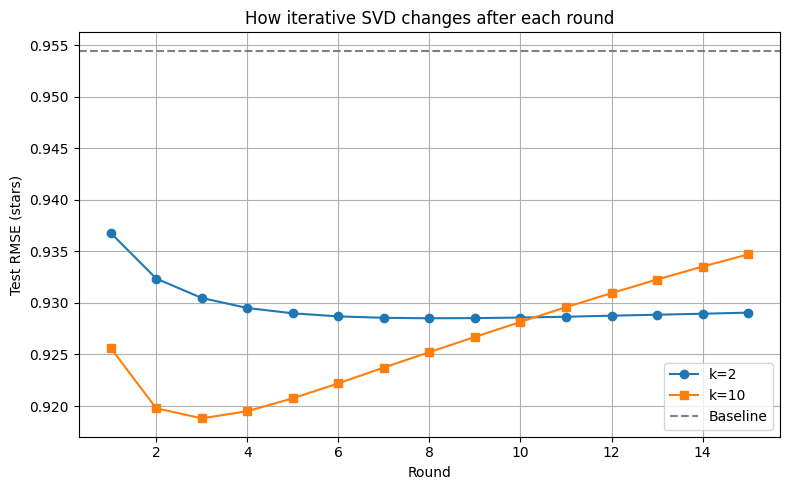

k=2: best round=8, best RMSE=0.9285, round 15 RMSE=0.9291
k=10: best round=3, best RMSE=0.9188, round 15 RMSE=0.9347


In [15]:
# Reuse the errors saved when I ran Model 3
history2 = round_errors[2]
history10 = round_errors[10]

rounds = np.arange(1, 16)

plt.figure(figsize=(8, 5))
plt.plot(rounds, history2, "o-", label="k=2")
plt.plot(rounds, history10, "s-", label="k=10")
plt.axhline(base_error, linestyle="--", color="gray", label="Baseline")
plt.xlabel("Round")
plt.ylabel("Test RMSE (stars)")
plt.title("How iterative SVD changes after each round")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

for k, errors in [(2, history2), (10, history10)]:
    r = int(np.argmin(errors)) + 1
    print(f"k={k}: best round={r}, best RMSE={min(errors):.4f}, "
          f"round 15 RMSE={errors[-1]:.4f}")

A model can improve for a few rounds and then start getting worse. I used the curve to check whether stopping at round 15 is sensible; the turn upward is similar to the overfitting behavior in the earlier rank-k graph.

In [16]:
r2 = int(np.argmin(history2)) + 1
r10 = int(np.argmin(history10)) + 1
msg2 = "yes" if r2 == 15 else "no"
msg10 = "yes" if r10 == 15 else "no"
display(Markdown(
    f"**Exercise 3 answer:** For **k=2**, the lowest RMSE was "
    f"**{min(history2):.4f}** at round **{r2}**, compared with "
    f"**{history2[-1]:.4f}** at round 15 (is round 15 best? **{msg2}**). "
    f"For **k=10**, the lowest RMSE was **{min(history10):.4f}** "
    f"at round **{r10}**, compared with **{history10[-1]:.4f}** "
    f"at round 15 (is round 15 best? **{msg10}**). "
    f"For k=10, the error rising after the early rounds looks like overfitting: "
    f"more iterations fit the known data better without improving hidden ratings."
))

**Exercise 3 answer:** For **k=2**, the lowest RMSE was **0.9285** at round **8**, compared with **0.9291** at round 15 (is round 15 best? **no**). For **k=10**, the lowest RMSE was **0.9188** at round **3**, compared with **0.9347** at round 15 (is round 15 best? **no**). For k=10, the error rising after the early rounds looks like overfitting: more iterations fit the known data better without improving hidden ratings.

## Exercise 4: Choose k using validation, not test ratings

In [17]:
# Hide part of the training ratings as a validation set
fit, val = split_ratings(train, seed=1)
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
B_fit = baseline_matrix(R_fit)
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U_fit, s_fit, Vt_fit = np.linalg.svd(X_fit, full_matrices=False)

# Positions for validation ratings, separate from the final test ratings
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1
val_truth = val["rating"].to_numpy()

def val_score(P):
    return rmse(np.clip(P[val_u, val_i], 1, 5), val_truth)

val_errors = []
for k in ks:
    P_val = rank_k(U_fit, s_fit, Vt_fit, k) + B_fit
    val_errors.append(val_score(P_val))

best_k = ks[int(np.argmin(val_errors))]
print(pd.DataFrame({"k": ks, "validation RMSE": val_errors}).to_string(index=False))
print("Chosen k:", best_k)

# Now use the full original training matrix with the chosen k
P_honest = rank_k(U2, s2, Vt2, best_k) + B
honest_test_rmse = score(P_honest)
print("Final test RMSE:", round(honest_test_rmse, 4))

  k  validation RMSE
  1         0.963243
  2         0.957022
  3         0.955828
  5         0.952637
 10         0.951080
 15         0.949224
 20         0.950360
 30         0.957233
 50         0.958268
100         0.968026
200         0.973084
400         0.973063
943         0.973125
Chosen k: 15
Final test RMSE: 0.925


The first comparison used the test set to decide which k looked best. That lets the test ratings affect my choice. Here I use a validation split inside the training data, choose k with validation RMSE, and only then evaluate the chosen rank on the original test set.

In [18]:
comparison = "lower than" if honest_test_rmse < 0.9332 else (
    "higher than" if honest_test_rmse > 0.9332 else "equal to"
)
display(Markdown(
    f"**Exercise 4 answer:** Validation picked **k={best_k}**. The handout "
    f"used k=10. After refitting with all the original training ratings, "
    f"Model 2 scored **{honest_test_rmse:.4f}** on my test set, which is "
    f"**{comparison}** 0.9332 in the handout. "
    f"The two scores come from different test splits."
))

**Exercise 4 answer:** Validation picked **k=15**. The handout used k=10. After refitting with all the original training ratings, Model 2 scored **0.9250** on my test set, which is **lower than** 0.9332 in the handout. The two scores come from different test splits.

## Exercise 5: Repeat Model 2 with a different seed

In [19]:
# Make a new train/test split with seed 1
train1, test1 = split_ratings(ratings, seed=1)
R1 = to_matrix(train1)
known1 = ~np.isnan(R1)
B1 = baseline_matrix(R1)
X1 = np.where(known1, R1 - B1, 0.0)
U_new, s_new, Vt_new = np.linalg.svd(X1, full_matrices=False)

# Keep the k selected using validation in Exercise 4
P_new = rank_k(U_new, s_new, Vt_new, best_k) + B1
new_u = test1["user"].to_numpy() - 1
new_i = test1["item"].to_numpy() - 1
new_truth = test1["rating"].to_numpy()

def new_score(P):
    return rmse(np.clip(P[new_u, new_i], 1, 5), new_truth)

baseline_old, model_old = score(B), honest_test_rmse
baseline_new, model_new = new_score(B1), new_score(P_new)
old_gain = 100 * (baseline_old - model_old) / baseline_old
new_gain = 100 * (baseline_new - model_new) / baseline_new

print(f"seed 0: baseline={baseline_old:.4f}, model 2={model_old:.4f}, "
      f"improvement={old_gain:.2f}%")
print(f"seed 1: baseline={baseline_new:.4f}, model 2={model_new:.4f}, "
      f"improvement={new_gain:.2f}%")
print("Change in model RMSE:", round(abs(model_new - model_old), 4))

seed 0: baseline=0.9545, model 2=0.9250, improvement=3.09%
seed 1: baseline=0.9577, model 2=0.9279, improvement=3.11%
Change in model RMSE: 0.0029


Changing the seed changes which ratings are held out. If Model 2 still improves on the baseline, that is evidence that its advantage is not limited to one lucky split.

In [20]:
wins = "still beat" if model_new < baseline_new else "did not beat"
seed_change = abs(model_new - model_old)
model_gain = baseline_new - model_new
relative = "larger" if model_gain > seed_change else "smaller"
display(Markdown(
    f"**Exercise 5 answer:** With seed 1, Model 2 **{wins}** the baseline "
    f"(**{model_new:.4f}** versus **{baseline_new:.4f}**). "
    f"Its improvement was **{new_gain:.2f}%** compared with **{old_gain:.2f}%** "
    f"on the first split. The change in Model 2's RMSE between seeds "
    f"was **{seed_change:.4f}**, while its advantage on seed 1 was "
    f"**{model_gain:.4f}** RMSE, which is **{relative}** than the seed-to-seed change."
))

**Exercise 5 answer:** With seed 1, Model 2 **still beat** the baseline (**0.9279** versus **0.9577**). Its improvement was **3.11%** compared with **3.09%** on the first split. The change in Model 2's RMSE between seeds was **0.0029**, while its advantage on seed 1 was **0.0298** RMSE, which is **larger** than the seed-to-seed change.

## Exercise 6: What does an RMSE of 0.93 mean?

An RMSE of 0.93 stars means the predicted movie ratings are off by roughly one star on the five-star scale, with bigger mistakes counting more. The recommender is getting fairly close to people's ratings on average, but it still makes mistakes.

---
## Final comparison

In [21]:
# Put the main results together in one table
summary = pd.DataFrame([
    ["Baseline", "—", base_error],
    ["Model 1: movie averages", best1_k, min(err1)],
    ["Model 2: residual SVD", best2_k, min(err2)],
    ["Model 3: iterative (15 rounds)", best3_k, model3_errors[best3_k]],
    ["Model 2: validation-chosen k", best_k, honest_test_rmse],
], columns=["Model", "k", "Test RMSE"])
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                         Model  k  Test RMSE
                      Baseline  —     0.9545
       Model 1: movie averages 10     0.9726
         Model 2: residual SVD 15     0.9250
Model 3: iterative (15 rounds)  5     0.9206
  Model 2: validation-chosen k 15     0.9250


## What I found

With k = 15 chosen on validation ratings, Model 2 got a test RMSE of 0.9250 stars. That's about 3.1% lower than the 0.9545 baseline. Iterative SVD reached 0.9206 with k = 5 after 15 rounds, with the rank picked from the test results.